In [ ]:
import os
DATA_DIR = "D:/M2/Data Mining/DM-Weather-framework/data"

os.makedirs(DATA_DIR, exist_ok=True)

Mounted at /content/drive


In [ ]:
%pip install -q "cdsapi>=0.7.0" xarray cfgrib eccodes
!apt-get -qq install -y libeccodes-dev

Selecting previously unselected package libeccodes-data.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../libeccodes-data_2.34.1-1build2_all.deb ...
Unpacking libeccodes-data (2.34.1-1build2) ...
Selecting previously unselected package libeccodes0:amd64.
Preparing to unpack .../libeccodes0_2.34.1-1build2_amd64.deb ...
Unpacking libeccodes0:amd64 (2.34.1-1build2) ...
Selecting previously unselected package libeccodes-dev:amd64.
Preparing to unpack .../libeccodes-dev_2.34.1-1build2_amd64.deb ...
Unpacking libeccodes-dev:amd64 (2.34.1-1build2) ...
Setting up libeccodes-data (2.34.1-1build2) ...
Setting up libeccodes0:amd64 (2.34.1-1build2) ...
Setting up libeccodes-dev:amd64 (2.34.1-1build2) ...
Processing triggers for libc-bin (2.39-0ubuntu8.9) ...
/sbin/ldconfig.real: /usr/local/lib/libumf.so.1 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_loader.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbb.so

In [ ]:
%pip install -q geopandas regionmask

In [ ]:
%pip install -q cdsapi geopandas netcdf4 h5netcdf

In [5]:
import os, glob, math, zipfile, tempfile
from datetime import date
import numpy as np
import xarray as xr
import geopandas as gpd
import cdsapi
from shapely import contains_xy
from shapely.ops import unary_union
from google.colab import drive, userdata
import xarray as xr, geopandas as gpd, regionmask, glob


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [26]:
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

In [ ]:
BASE    = "D:/M2/Data Mining/DM-Weather-framework/data"

DATA_DIR = f"{BASE}/data_nc"        # fichiers bruts NetCDF (nouveau dossier)
OUT_DIR  = f"{BASE}/processed"
SHP      = f"{BASE}/dz_shp/dz.shp"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

START_YEAR = 2015
LAG_MONTHS = 2
FACTOR     = 2
VARS = ["t2m","d2m","sp","u10","v10","slhf","sshf","ssr","str","e","ro","tp"]

In [7]:
# path du dataset initial
PATH = f"{OUT_DIR}/era5land_algeria_masked_x2.nc"
ds_dz = xr.open_dataset(PATH)
print(ds_dz)
print(list(ds_dz.data_vars))

<xarray.Dataset> Size: 64MB
Dimensions:    (time: 140, latitude: 92, longitude: 104)
Coordinates:
  * time       (time) datetime64[ns] 1kB 2015-01-01 2015-02-01 ... 2026-08-01
  * latitude   (latitude) float64 736B 18.95 19.15 19.35 ... 36.75 36.95 37.1
  * longitude  (longitude) float64 832B -8.65 -8.45 -8.25 ... 11.55 11.75 11.95
Data variables:
    t2m        (time, latitude, longitude) float32 5MB ...
    d2m        (time, latitude, longitude) float32 5MB ...
    sp         (time, latitude, longitude) float32 5MB ...
    u10        (time, latitude, longitude) float32 5MB ...
    v10        (time, latitude, longitude) float32 5MB ...
    slhf       (time, latitude, longitude) float32 5MB ...
    sshf       (time, latitude, longitude) float32 5MB ...
    ssr        (time, latitude, longitude) float32 5MB ...
    str        (time, latitude, longitude) float32 5MB ...
    e          (time, latitude, longitude) float32 5MB ...
    ro         (time, latitude, longitude) float32 5MB ...
 

# **Data Analysis**

## **Univariante analysis**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [9]:
df = ds_dz[VARS].to_dataframe().reset_index().dropna()

In [ ]:
pd.set_option("display.float_format", "{:.4g}".format)

VARS = ["t2m","d2m","sp","u10","v10","slhf","sshf","ssr","str","e","ro","tp"]

# Une ligne par (mois, point de grille), uniquement les 12 variables
#df = ds_dz[VARS].to_dataframe().reset_index().dropna()
data = df[VARS].copy()

# Kelvin -> °C
data[["t2m","d2m"]] -= 273.15

print(data.shape)
data.head()

(759500, 12)


,t2m,d2m,sp,u10,v10,slhf,sshf,ssr,str,e,ro,tp
60,16.05,-7.532,9.632e+04,-3.544,-2.43,-5.668e+04,-1.886e+06,1.138e+07,-9.657e+06,-2.267e-05,0,1.218e-06
163,15.85,-7.612,9.607e+04,-3.434,-2.398,-5.597e+04,-1.88e+06,1.134e+07,-9.618e+06,-2.238e-05,0,1.218e-06
164,15.84,-7.545,9.629e+04,-3.49,-2.384,-5.565e+04,-1.828e+06,1.122e+07,-9.557e+06,-2.225e-05,0,1.218e-06
165,15.92,-7.486,9.644e+04,-3.544,-2.398,-5.638e+04,-1.976e+06,1.14e+07,-9.582e+06,-2.255e-05,0,1.218e-06
166,16.02,-7.447,9.649e+04,-3.572,-2.442,-5.647e+04,-1.973e+06,1.142e+07,-9.608e+06,-2.258e-05,0,1.218e-06


moyenne, medaine, mode

In [ ]:
def mode_binned(s, bins=50):
    counts, edges = np.histogram(s, bins=bins)
    i = counts.argmax()
    return (edges[i] + edges[i+1]) / 2

central = pd.DataFrame({
    "Moyenne": data.mean(),
    "Médiane": data.median(),
    "Mode":    data.apply(mode_binned),
})
central

,Moyenne,Médiane,Mode
t2m,23.85,24.13,34.1
d2m,1.494,1.281,0.8383
sp,9.518e+04,9.59e+04,9.669e+04
u10,-1.019,-0.986,-0.04712
v10,-0.5126,-0.4638,-0.4406
slhf,-4.973e+05,-1.814e+05,-1.14e+05
sshf,-3.389e+06,-3.404e+06,-4.058e+06
ssr,1.35e+07,1.396e+07,1.608e+07
str,-9.51e+06,-9.917e+06,-1.204e+07
e,-0.0001988,-7.253e-05,-4.559e-05


5 nombres and IQR

In [ ]:
five = pd.DataFrame({
    "Min": data.min(),
    "Q1":  data.quantile(0.25),
    "Q2 (médiane)": data.quantile(0.50),
    "Q3":  data.quantile(0.75),
    "Max": data.max(),
})
five["IQR = Q3 - Q1"] = five["Q3"] - five["Q1"]
five

,Min,Q1,Q2 (médiane),Q3,Max,IQR = Q3 - Q1
t2m,0.275,16.37,24.13,31.71,41.03,15.35
d2m,-16.95,-1.765,1.281,4.507,22.58,6.271
sp,7.986e+04,9.336e+04,9.59e+04,9.756e+04,1.036e+05,4197
u10,-6.719,-2.126,-0.986,0.0664,7.477,2.192
v10,-4.673,-1.16,-0.4638,0.2003,3.313,1.36
slhf,-1.104e+07,-3.129e+05,-1.814e+05,-8.607e+04,-3608,2.268e+05
sshf,-1.438e+07,-4.652e+06,-3.404e+06,-1.831e+06,5.863e+06,2.821e+06
ssr,2.787e+06,1.011e+07,1.396e+07,1.684e+07,2.531e+07,6.729e+06
str,-1.5e+07,-1.16e+07,-9.917e+06,-7.946e+06,-2.139e+06,3.652e+06
e,-0.004416,-0.0001251,-7.253e-05,-3.442e-05,-1.443e-06,9.071e-05


variance and std

In [ ]:
dispersion = pd.DataFrame({
    "Variance":    data.var(),
    "std":  data.std(),
})
dispersion

,Variance,std
t2m,76.75,8.761
d2m,23.14,4.81
sp,1.125e+07,3354
u10,2.527,1.59
v10,1.096,1.047
slhf,9.689e+11,9.843e+05
sshf,3.746e+12,1.936e+06
ssr,1.81e+13,4.254e+06
str,6.824e+12,2.612e+06
e,1.55e-07,0.0003937


Visualisation:

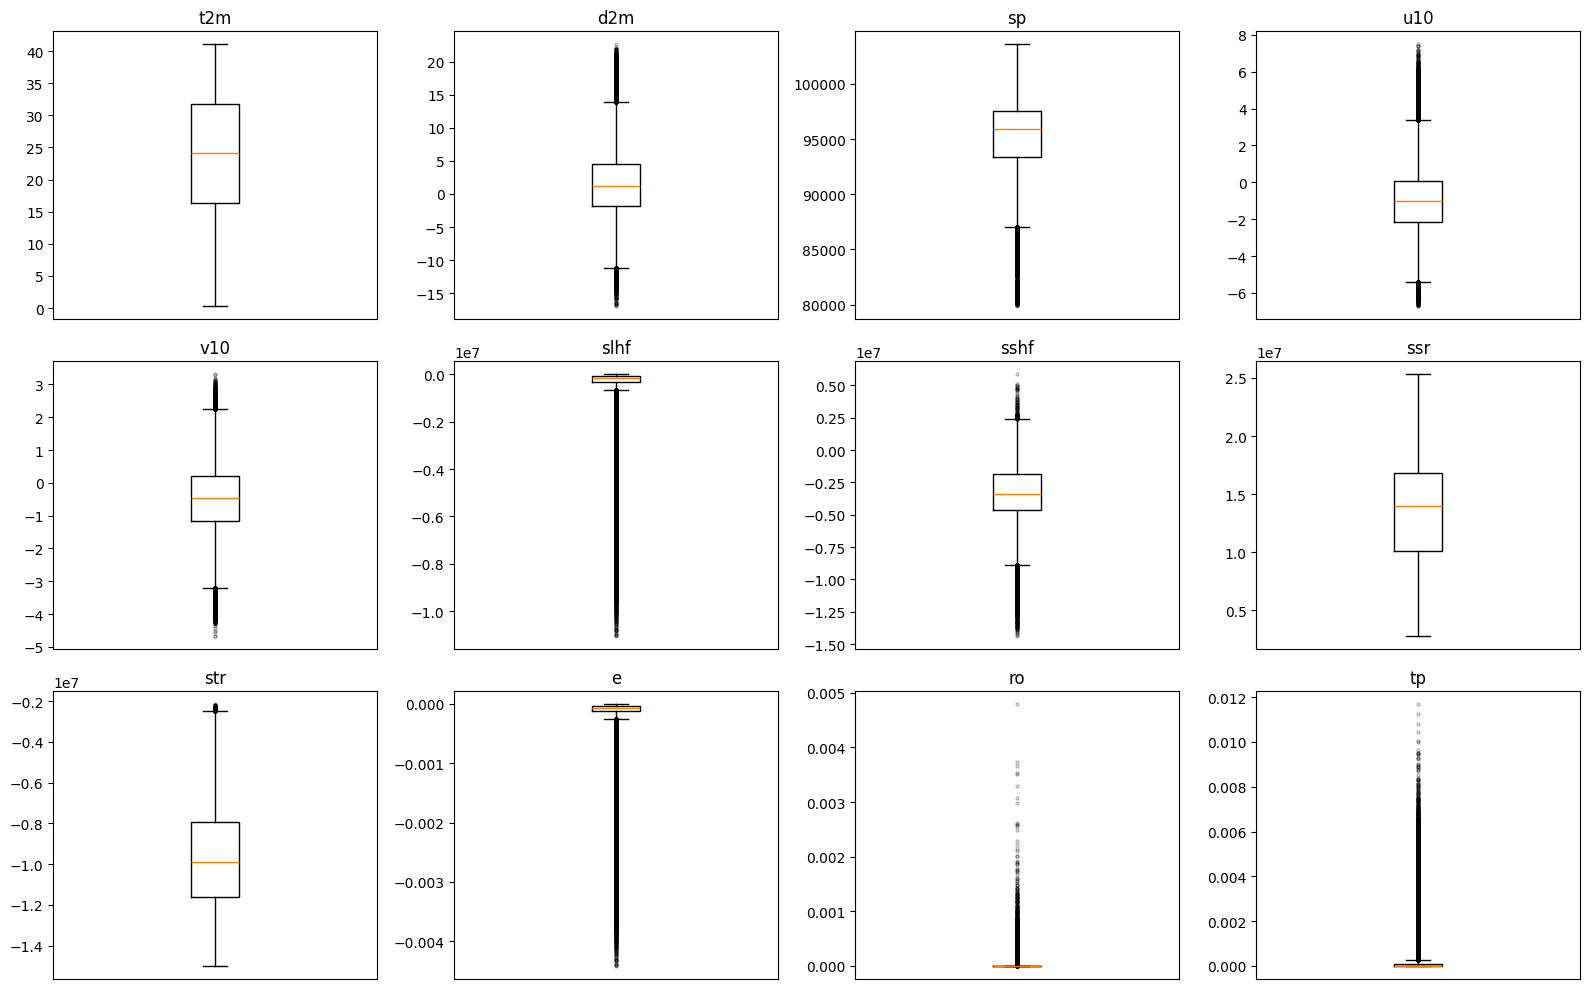

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, v in zip(axes.ravel(), VARS):
    ax.boxplot(data[v], vert=True, flierprops=dict(markersize=2, alpha=0.3))
    ax.set_title(v)
    ax.set_xticks([])
plt.tight_layout()
plt.show()

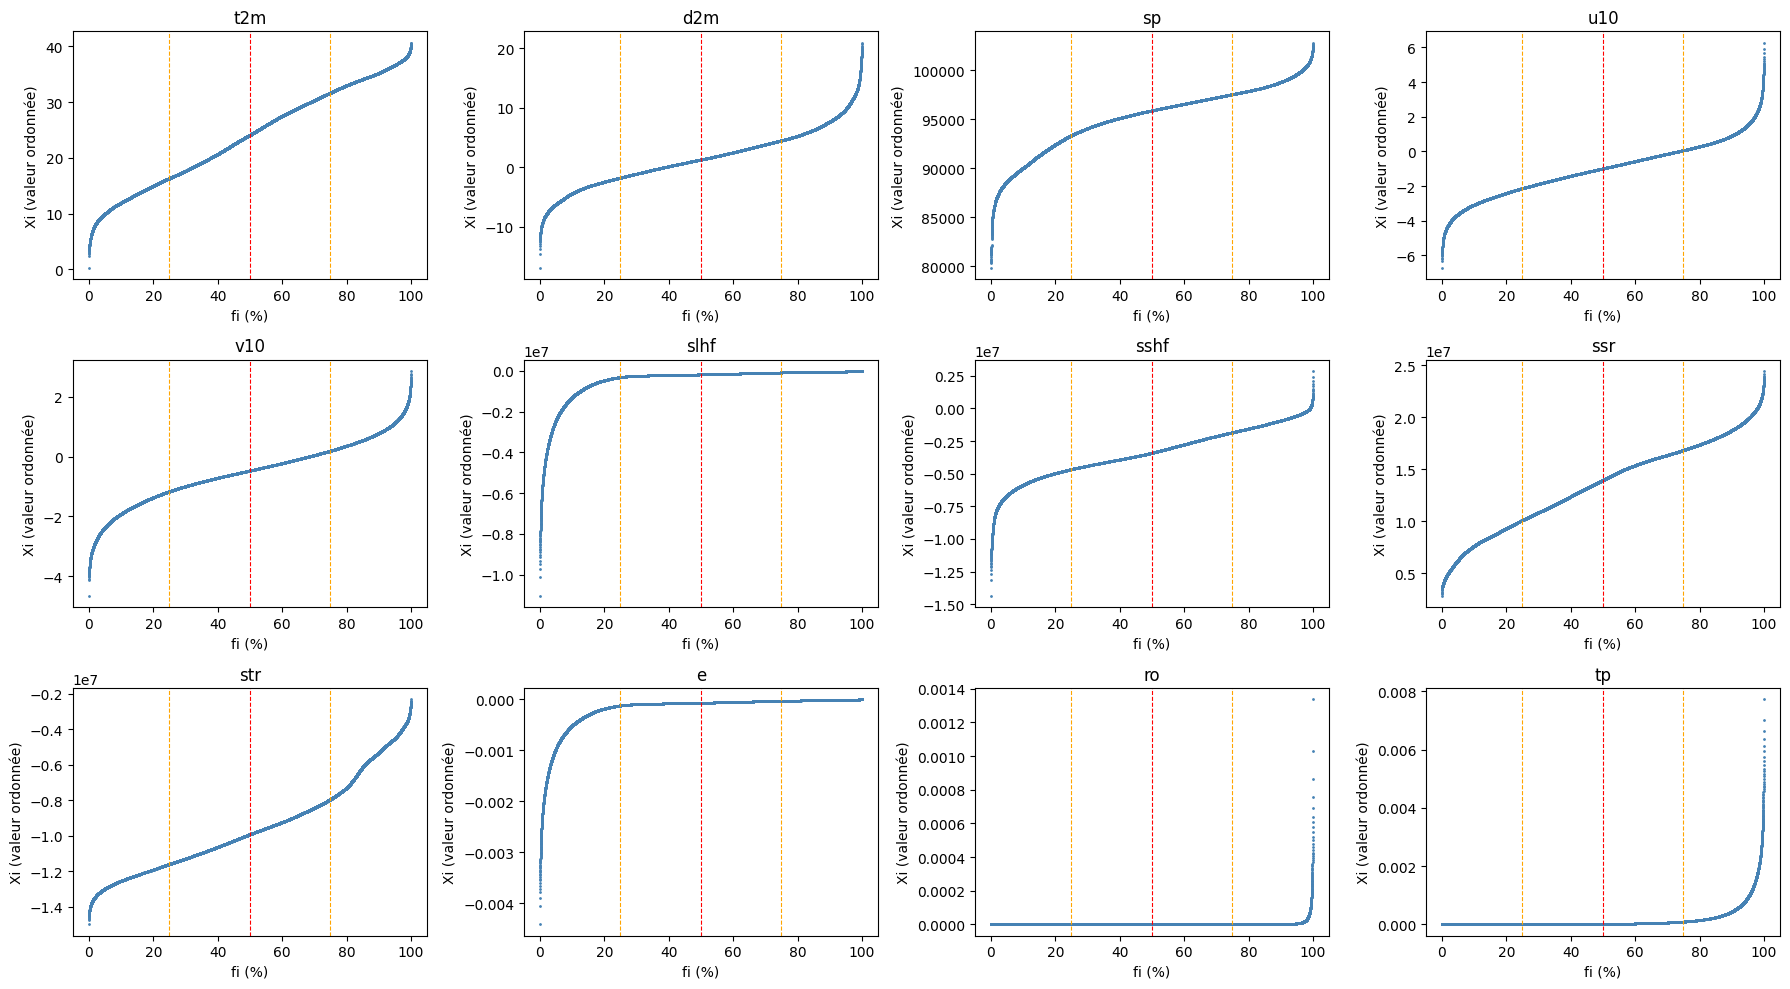

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(18, 10))

for ax, v in zip(axes.ravel(), VARS):
    x = np.sort(data[v].values)          # valeurs ordonne Xi
    n = len(x)
    i = np.arange(1, n + 1)              # rang i = 1..n
    f = (i - 0.5) / n * 100              # fi en %
    step = 50
    ax.plot(f[::step], x[::step], ".", markersize=2, color="steelblue")

    # Q1, Q2, Q3
    for fq, c in [(25, "orange"), (50, "red"), (75, "orange")]:
        ax.axvline(fq, color=c, ls="--", lw=0.8)

    ax.set_title(v)
    ax.set_xlabel("fi (%)")
    ax.set_ylabel("Xi (valeur ordonnée)")

plt.tight_layout()
plt.show()

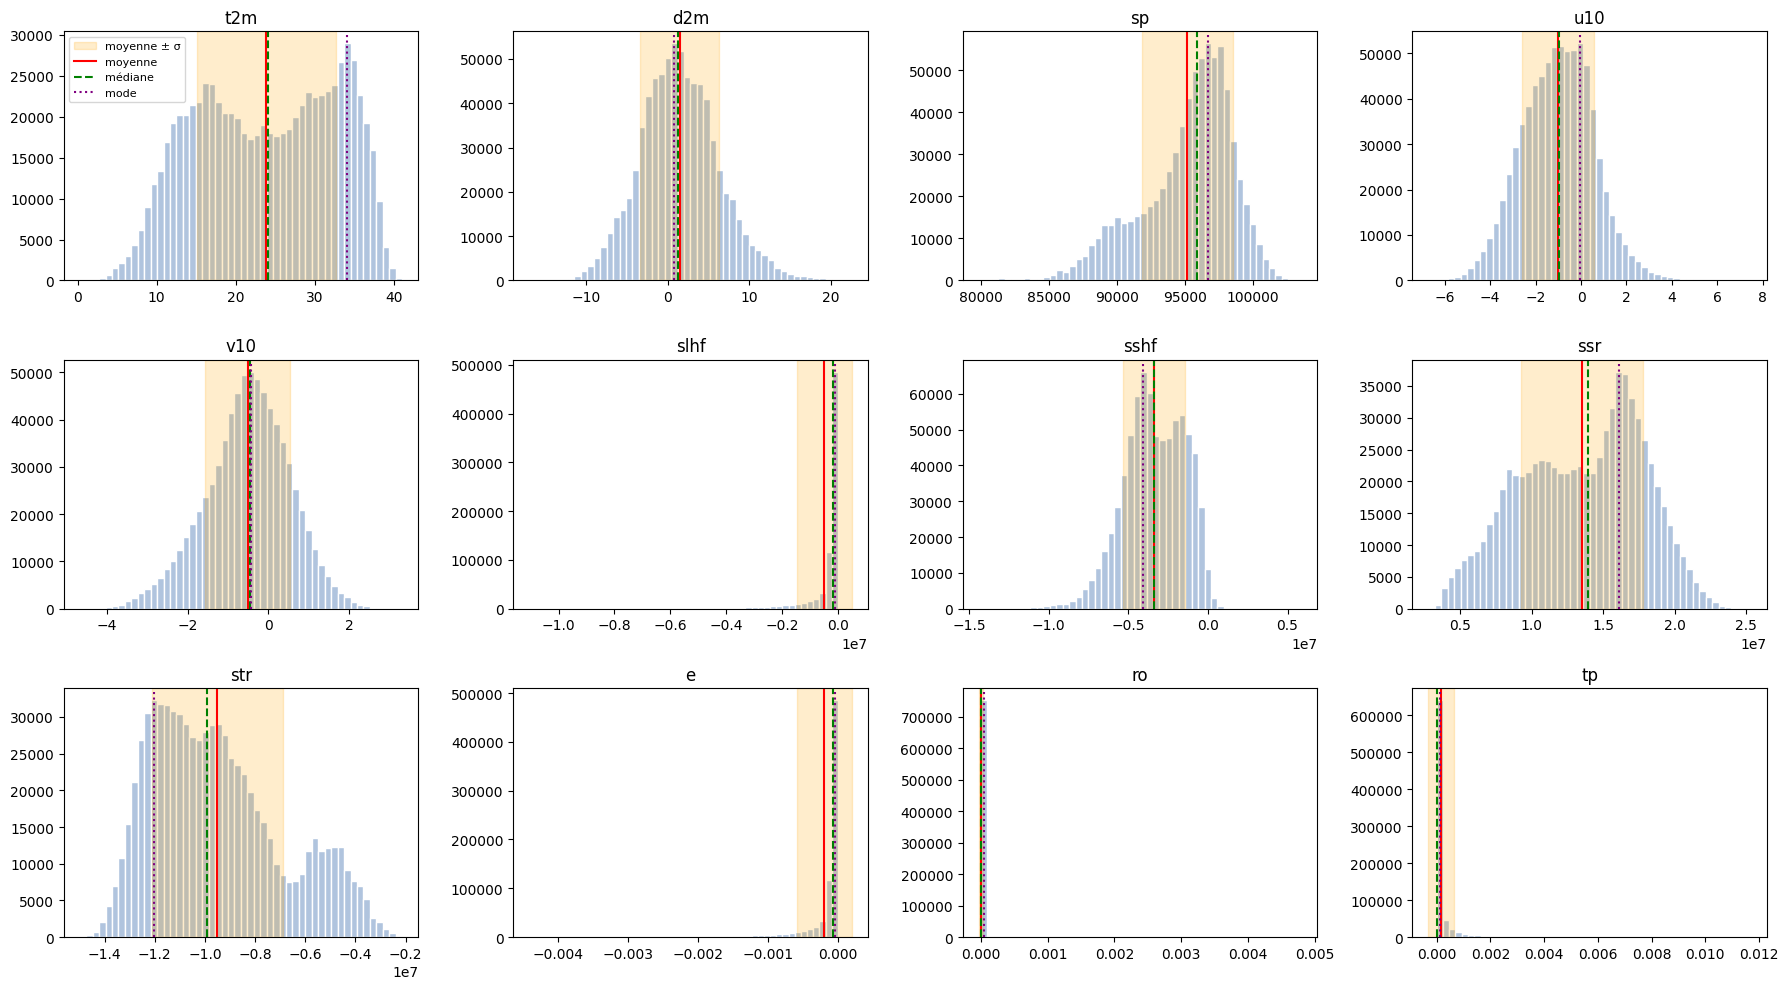

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(18, 10))
for ax, v in zip(axes.ravel(), VARS):
    m, sd = data[v].mean(), data[v].std()
    ax.hist(data[v], bins=50, color="lightsteelblue", edgecolor="white")
    ax.axvspan(m - sd, m + sd, color="orange", alpha=0.2, label="moyenne ± σ")
    ax.axvline(m, color="red", label="moyenne")
    ax.axvline(data[v].median(), color="green", ls="--", label="médiane")
    ax.axvline(mode_binned(data[v]), color="purple", ls=":", label="mode")
    ax.set_title(v)
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## **Bivariante analysis**

***Préparation des données pour l'analyse bivariée***

**Ce que fait cette cellule :**
- Construit le tableau d'analyse : une ligne par point de grille et par mois, avec les 12 variables (`t2m` et `d2m` converties en °C).
- Crée la variable `month` (1 à 12), extraite de la date.
- Crée la **cible** `t2m_next` : la température du mois suivant, au même point de grille (en vérifiant que les deux mois sont consécutifs).
- Découpe cette cible en **3 classes de largeur égale** (Low, Medium, High) : c'est la variable catégorielle `classe`.

**Pourquoi elle est importante pour l'analyse bivariée :**
- Elle fournit la variable `t2m_next`, nécessaire pour étudier la relation entre chaque variable et la température à prédire (scatter plots, corrélations de Pearson et Spearman).
- Elle fournit la variable catégorielle `classe`, nécessaire pour les analyses catégorielle–numérique (boxplots, test t) et catégorielle–catégorielle (chi-deux avec `month`).
- Sans elle, aucune des variables du jeu de données n'est catégorielle : on ne pourrait faire que du numérique–numérique.

In [12]:
import itertools
from scipy import stats

b = df[["time", "latitude", "longitude"] + VARS].copy()
b[["t2m", "d2m"]] -= 273.15                       # Kelvin -> °C

b = b.sort_values(["latitude", "longitude", "time"]).reset_index(drop=True)
b["month"] = b["time"].dt.month

# Target: t2m of the NEXT month at the same grid point
b["t_idx"] = b["time"].dt.year * 12 + b["time"].dt.month
g = b.groupby(["latitude", "longitude"])
b["t2m_next"] = g["t2m"].shift(-1)
consecutive = (g["t_idx"].shift(-1) - b["t_idx"]) == 1   # the next row must be exactly 1 month later
b = b[consecutive].drop(columns="t_idx").reset_index(drop=True)

# 3 equal-width classes on the range of the target
b["classe"], edges = pd.cut(b["t2m_next"], bins=3, labels=["Low", "Medium", "High"], retbins=True)
print("Class limits (°C):", np.round(edges, 2))
print(b["classe"].value_counts().sort_index())
print(b.shape)

Class limits (°C): [ 0.23 13.86 27.44 41.03]
classe
Low       117566
Medium    330609
High      305900
Name: count, dtype: int64
(754075, 18)


**Which method for which question**

| Variable types | Tool | Why |
|---|---|---|
| Num – Num | Scatter plot | shows the shape of the relation (linear, curved, none) |
| Num – Num | Pearson / Spearman | measures strength and direction, from -1 to +1 |
| Num – Num | Q-Q plot | compares the distributions of two variables of the same nature |
| Cat – Num | Boxplot | compares the distribution of a feature across the classes |
| Cat – Num | t-test | tests whether the means differ between classes |
| Cat – Cat | Chi-square + stacked bar chart | tests independence between class and month |

### **Numerical – Numerical**

we calculate the skewness and the kurtosis ( l’aplatissement) pour determnier quelle methode de corelation est plus adapter:

* **Si une variable est très asymétrique, elle n’est pas normale, donc Spearman est plus adapté que Pearson**

In [13]:
shape = pd.DataFrame({"Skewness": b[VARS].skew(),
                      "Kurtosis": b[VARS].kurt()})
shape["Roughly normal ?"] = (shape["Skewness"].abs() < 1) & (shape["Kurtosis"].abs() < 3)
shape

,Skewness,Kurtosis,Roughly normal ?
t2m,-0.106478,-1.158241,True
d2m,0.295457,0.324238,True
sp,-0.840795,0.473469,True
u10,0.079275,0.155686,True
v10,-0.241914,0.042863,True
slhf,-4.065449,20.082071,False
sshf,-0.461054,0.258607,True
ssr,-0.193135,-0.846031,True
str,0.571238,-0.529085,True
e,-4.065685,20.084421,False


La plupart des variables sont à peu près symétriques. slhf, e, tp et surtout ro (asymétrie 36, kurtosis 2625) sont dominées par des zéros avec de rares valeurs extrêmes.

Pearson and Spearman correlation matrices

Ici on a fait ls deux mais la plus just est celle du spearman parceque , elle y a beaucoup de outliers et en general la data est noramlly distrbuted.

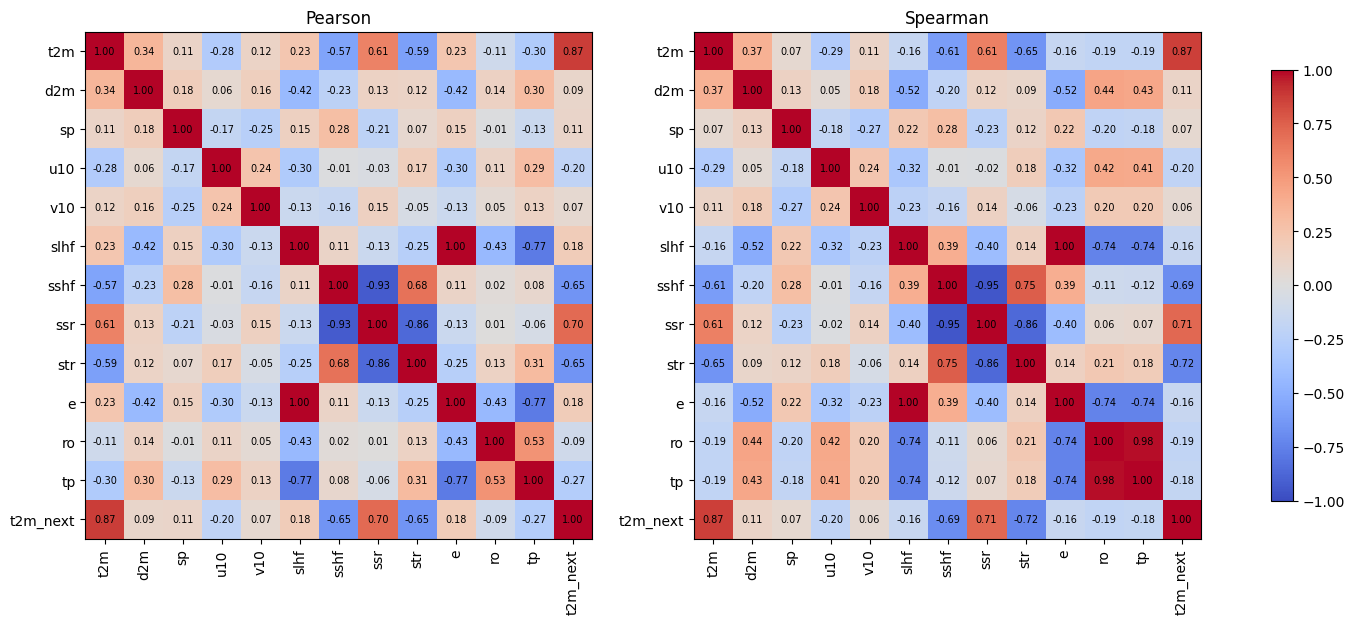

,Pearson,Spearman
t2m,0.867563,0.866625
d2m,0.094285,0.110184
sp,0.108858,0.069046
u10,-0.200186,-0.202656
v10,0.069233,0.058410
slhf,0.184582,-0.155212
sshf,-0.649399,-0.691997
ssr,0.704759,0.713967
str,-0.648676,-0.720092
e,0.184555,-0.155218


In [16]:
cols = VARS + ["t2m_next"]
pearson  = b[cols].corr(method="pearson")
spearman = b[cols].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, m, name in zip(axes, [pearson, spearman], ["Pearson", "Spearman"]):
    im = ax.imshow(m, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=90)
    ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols)
    for i in range(len(cols)):
        for j in range(len(cols)):
            ax.text(j, i, f"{m.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
    ax.set_title(name)
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

# Correlation of each feature with the target
pd.DataFrame({"Pearson": pearson["t2m_next"], "Spearman": spearman["t2m_next"]}).drop("t2m_next")

Force	Variables (Spearman):

* Forte (|ρ| ≥ 0.65): t2m 0.87, ssr +0.71, str −0.72, sshf −0.69
* Faible (0.1 à 0.3): u10 −0.20, ro −0.19, tp −0.18, slhf et e −0.16, d2m 0.11
* Quasi nulle	:sp 0.07, v10 0.06

scatter plots, each feature against the target

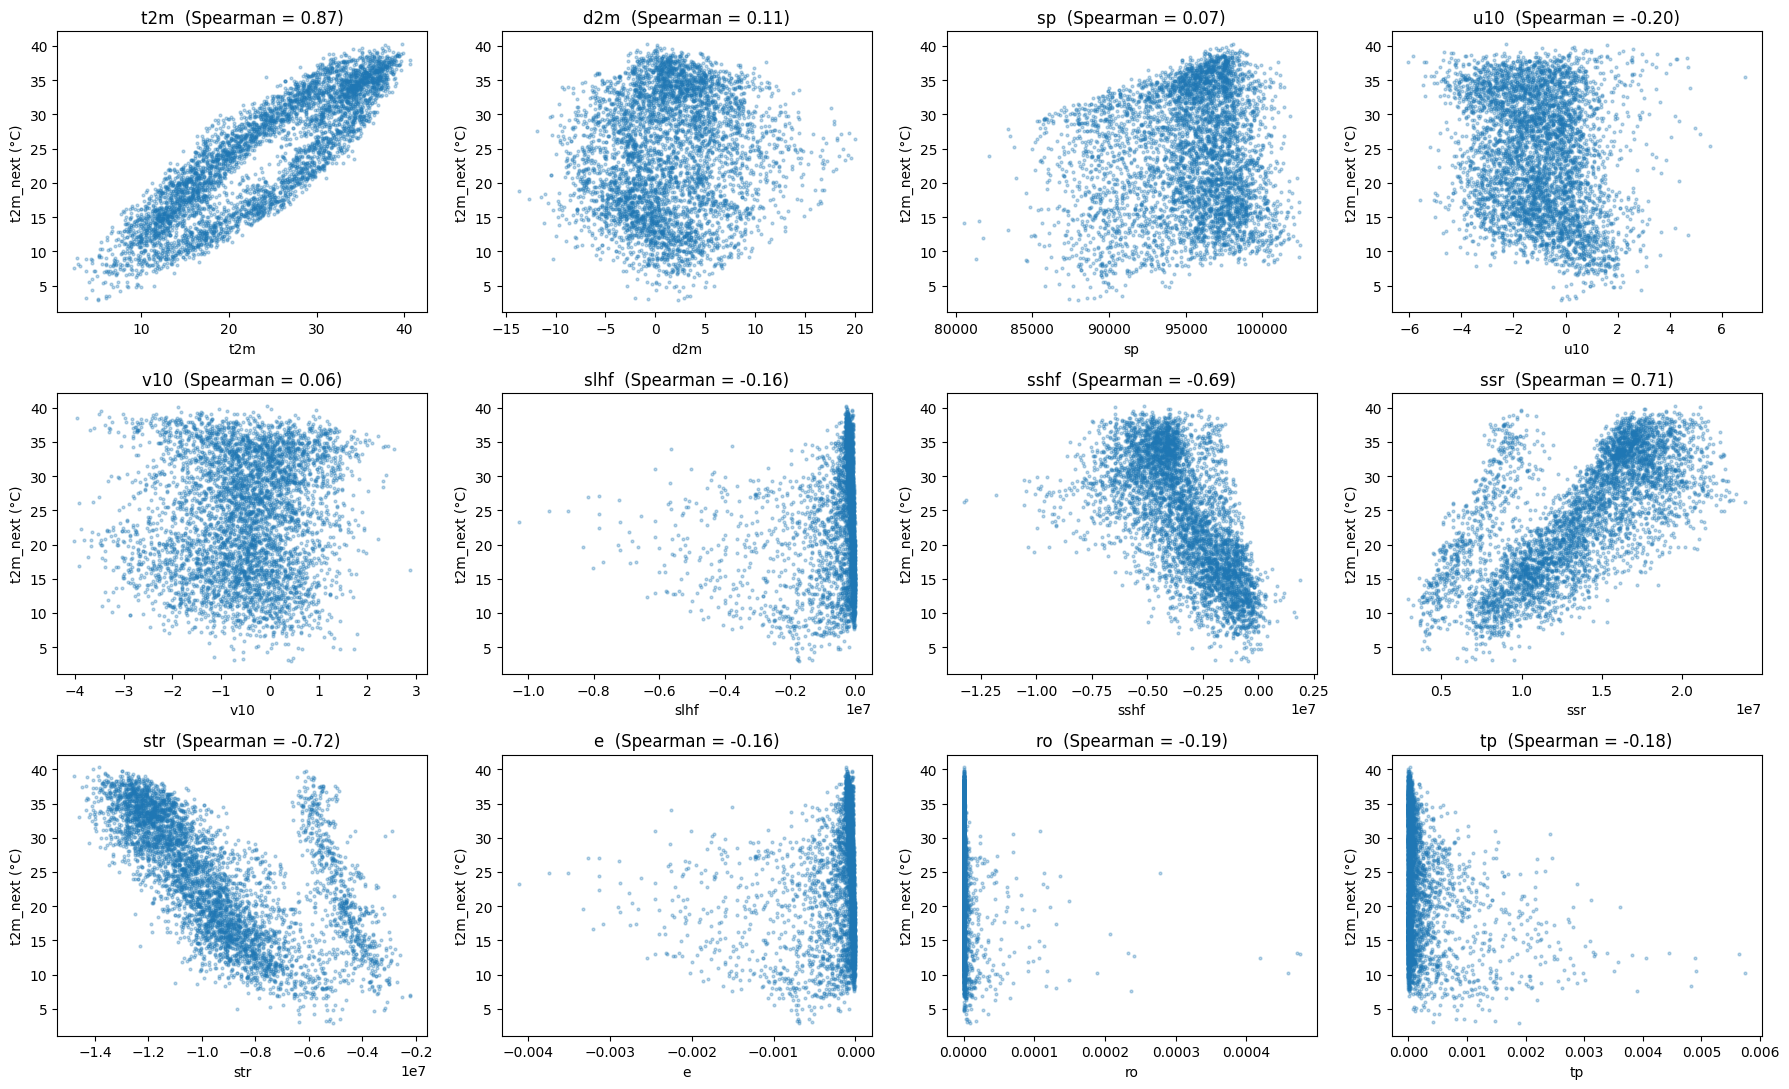

In [17]:
samp = b.sample(5000, random_state=0)

fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, v in zip(axes.ravel(), VARS):
    ax.scatter(samp[v], samp["t2m_next"], s=4, alpha=0.3)
    ax.set_title(f"{v}  (Spearman = {spearman.loc[v, 't2m_next']:.2f})")
    ax.set_xlabel(v); ax.set_ylabel("t2m_next (°C)")
plt.tight_layout()
plt.show()

* t2m forme une boucle à deux branches : pour une même température actuelle, le mois suivant est plus chaud au printemps et plus froid en automne. La variable month est donc nécessaire.
* ssr, str, sshf montrent une tendance nette, avec deux nuages. Colorer par mois permettrait de voir si ce sont des saisons ou des régions.
* d2m, sp, u10, v10 forment des nuages sans motif clair.
* slhf, e, ro, tp sont collées contre 0, avec quelques points extrêmes isolés.

scatter plots of the most correlated pairs of features

es paires viennent de la matrice de corrélation (Spearman) :

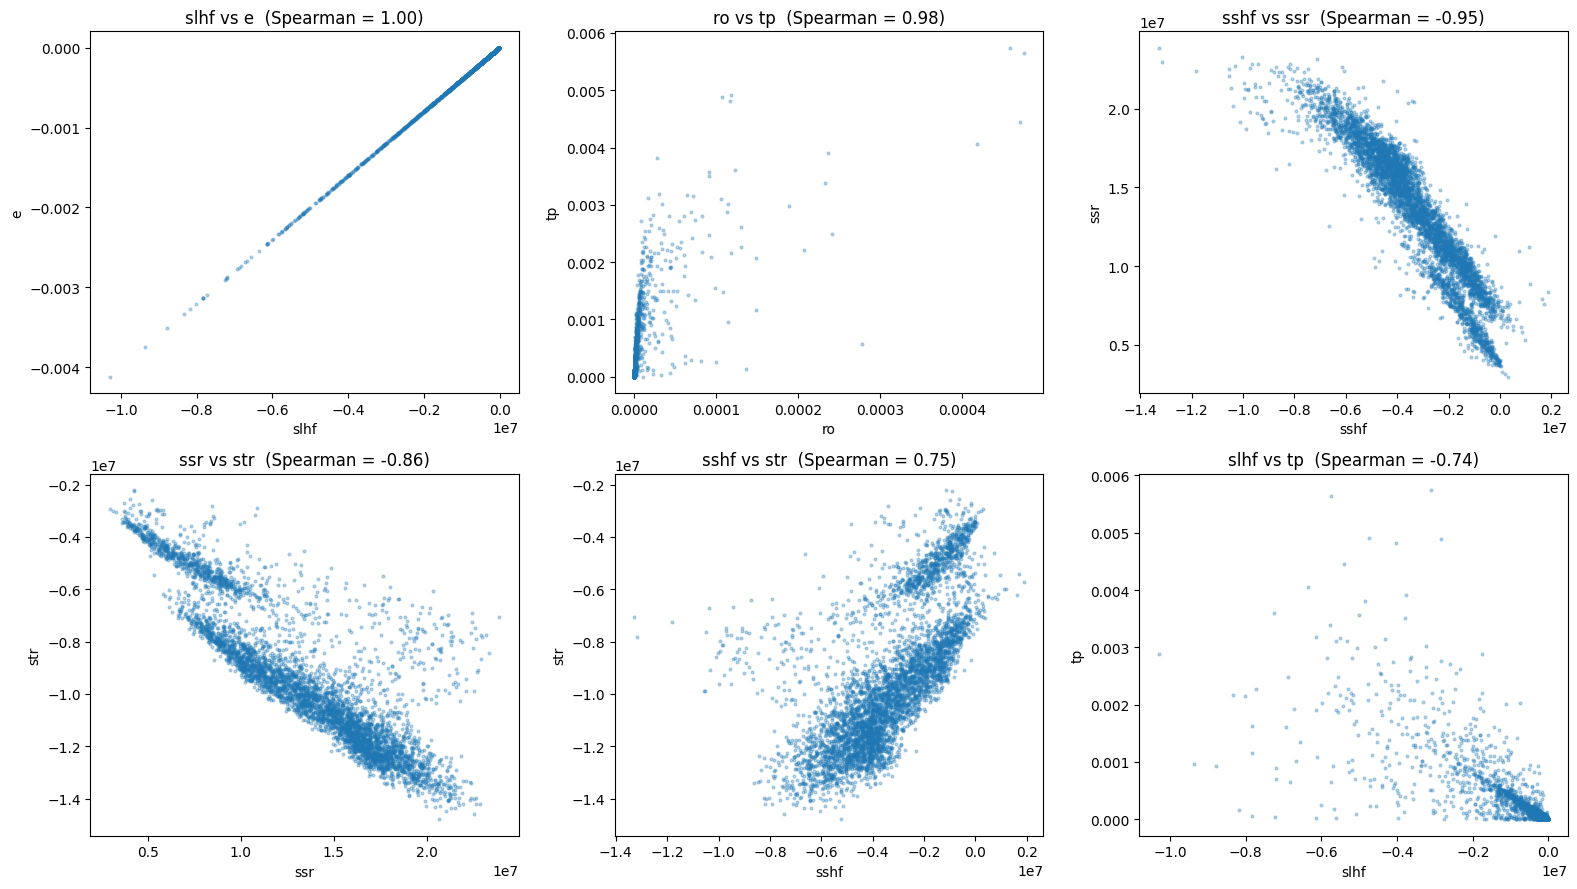

In [18]:
sp = spearman.loc[VARS, VARS]
upper = sp.where(np.triu(np.ones(sp.shape), k=1).astype(bool))
top = upper.stack().abs().sort_values(ascending=False).head(6).index

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (x, y) in zip(axes.ravel(), top):
    ax.scatter(samp[x], samp[y], s=4, alpha=0.3)
    ax.set_title(f"{x} vs {y}  (Spearman = {sp.loc[x, y]:.2f})")
    ax.set_xlabel(x); ax.set_ylabel(y)
plt.tight_layout()
plt.show()

Paire	ρ	Lecture:
* slhf – e	1.00	droite parfaite : même information (cohérent avec le fait que l’évaporation se déduit du flux de chaleur latente)
* ro – tp	0.98	le ruissellement suit les précipitations
* sshf – ssr	−0.95	le rayonnement solaire pilote la chaleur sensible
* ssr – str	−0.86	fortement liés
* sshf – str	0.75	liés
* slhf – tp	−0.74	liés

Q-Q plot (pairs of variables of the same nature)

***Choix des paires pour le Q-Q plot***

Le Q-Q plot compare deux variables **de même nature** (même type de grandeur et même unité).

| Paire | Ce qui les rapproche |
|---|---|
| `t2m` – `d2m` | deux températures à 2 m (°C) |
| `u10` – `v10` | deux composantes du vent à 10 m (m/s) |
| `ssr` – `str` | deux rayonnements nets à la surface (J/m²) |
| `slhf` – `sshf` | deux flux de chaleur à la surface (J/m²) |

Les autres variables n'ont pas de partenaire de même nature : `sp` est la seule pression, et `e`, `ro`, `tp` sont en mètres mais mesurent des phénomènes différents.

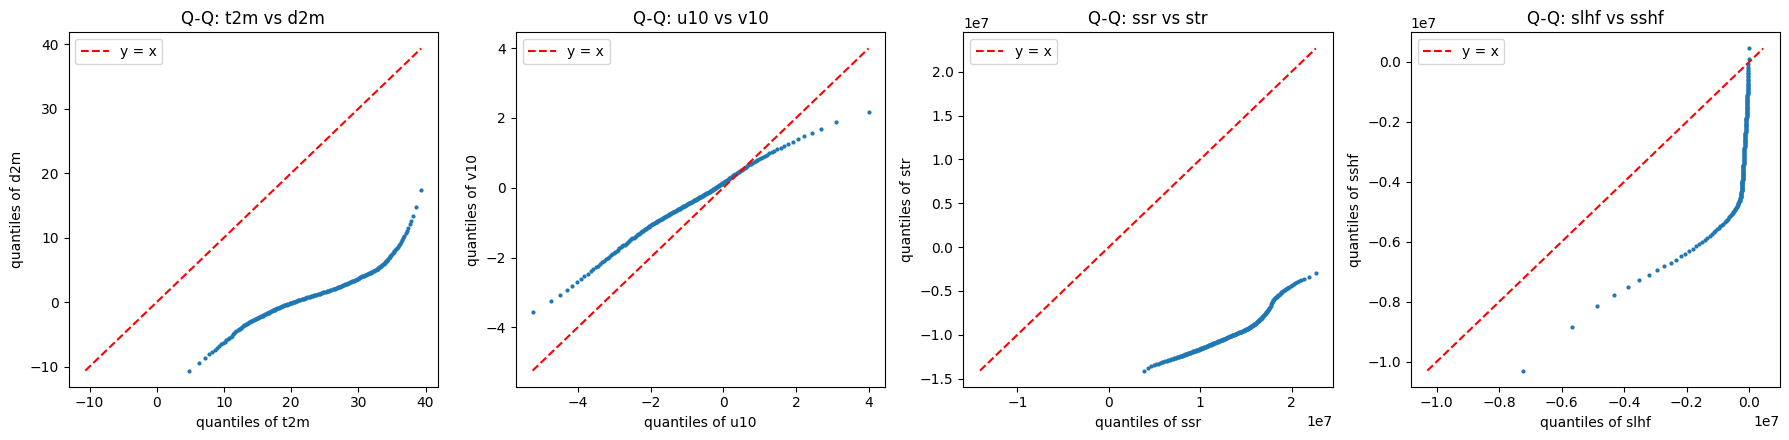

In [19]:
pairs_qq = [("t2m", "d2m"), ("u10", "v10"), ("ssr", "str"), ("slhf", "sshf")]
p = (np.arange(1, 201) - 0.5) / 200

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, (x, y) in zip(axes, pairs_qq):
    qx, qy = np.quantile(b[x], p), np.quantile(b[y], p)
    lo, hi = min(qx.min(), qy.min()), max(qx.max(), qy.max())
    ax.plot(qx, qy, ".", markersize=4)
    ax.plot([lo, hi], [lo, hi], "r--", label="y = x")
    ax.set_xlabel(f"quantiles of {x}"); ax.set_ylabel(f"quantiles of {y}")
    ax.set_title(f"Q-Q: {x} vs {y}"); ax.legend()
plt.tight_layout()
plt.show()

Paire	Lecture:

* t2m – d2m	points sous la droite et courbés : le point de rosée est toujours plus bas, avec une étendue plus étroite et une autre forme
* u10 – v10	presque une droite de pente < 1 : même forme, v10 moins dispersé que u10
* ssr – str	très loin de la droite : signes opposés (positif contre négatif)
* slhf – sshf	très courbé : slhf concentrée près de 0 avec une longue queue, sshf bien plus étalée

### **Categorical – Numerical**

boxplots of each feature by temperature class

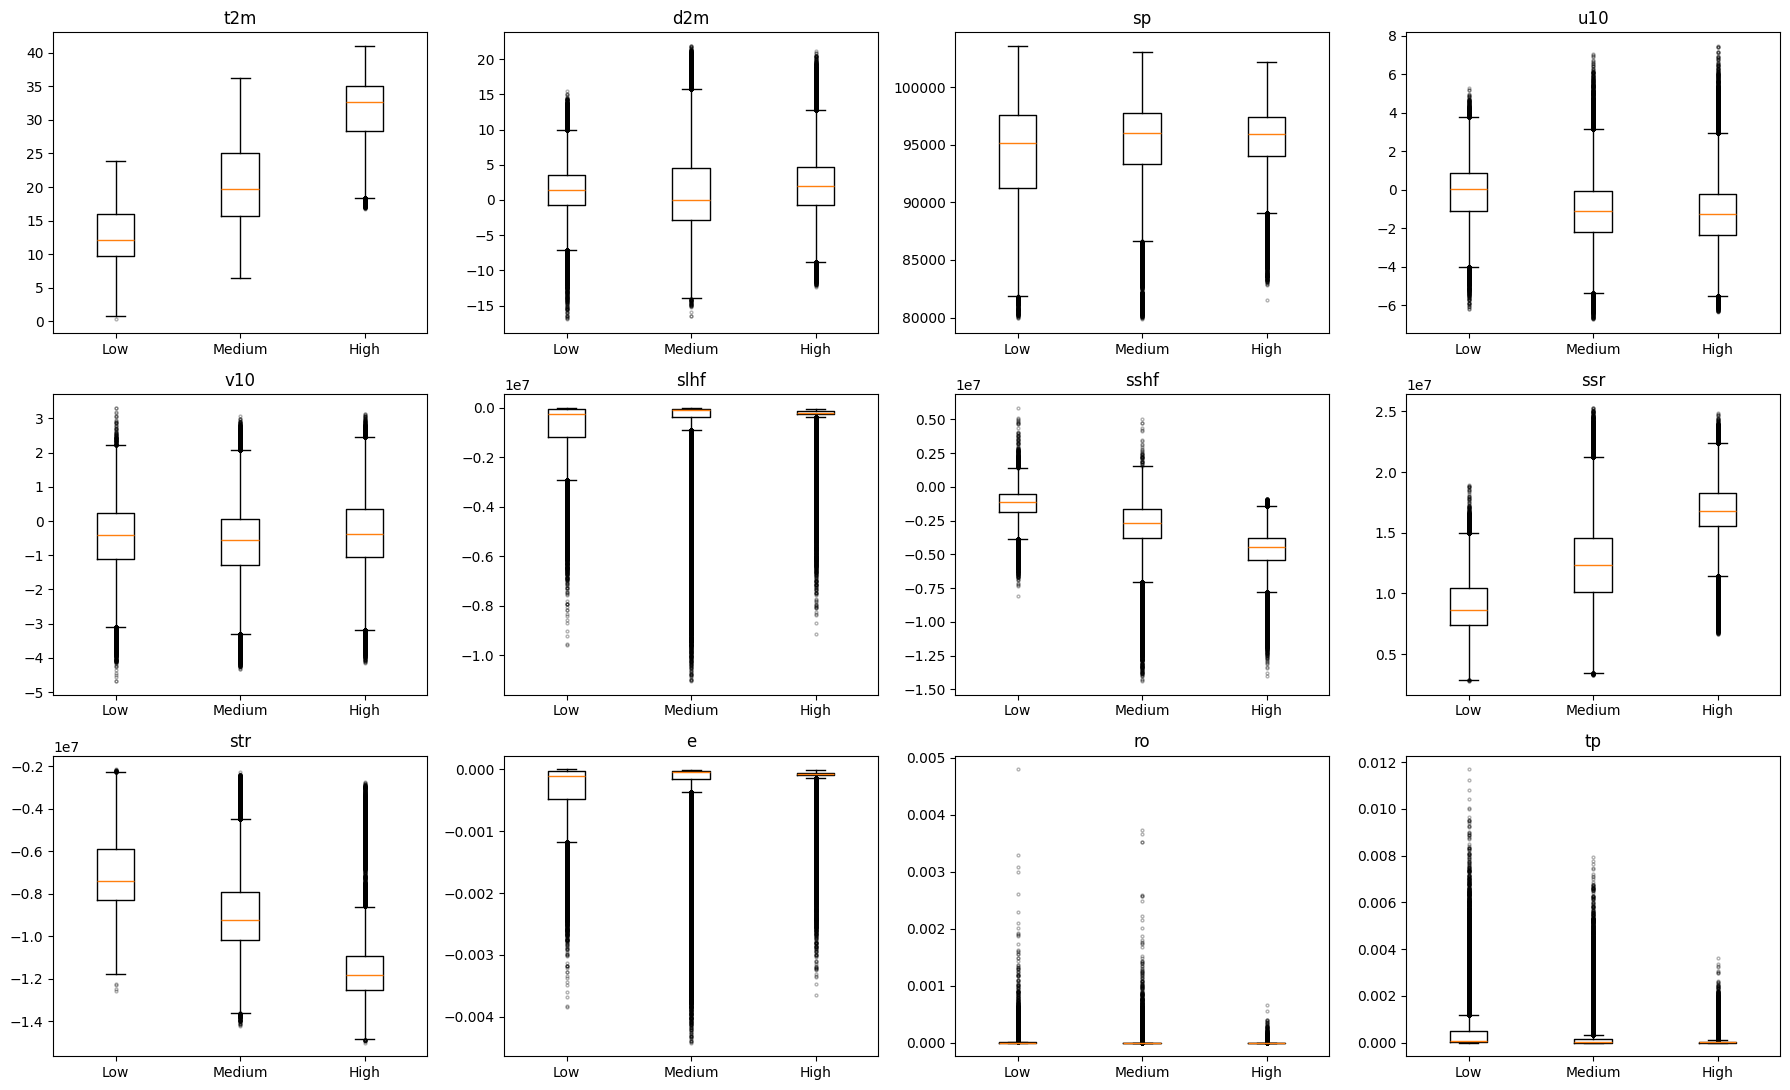

In [20]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, v in zip(axes.ravel(), VARS):
    groups = [b.loc[b["classe"] == c, v] for c in ["Low", "Medium", "High"]]
    ax.boxplot(groups, tick_labels=["Low", "Medium", "High"],
               flierprops=dict(markersize=2, alpha=0.3))
    ax.set_title(v)
plt.tight_layout()
plt.show()

* **Bien séparées, de Low à High :** t2m, ssr (croissante), sshf et str (décroissantes).
* **Séparation partielle :** u10 (Low se distingue, Medium ≈ High), sp et tp (faible).
* **Chevauchement total :** d2m, v10.
* **Boîtes écrasées près de 0 avec beaucoup de points extrêmes :** slhf, e, ro, tp.
* **Pour t2m,** les classes se recouvrent un peu (le Low monte jusqu’à environ 24 °C). t2m est la température du mois courant, et la classe celle du mois suivant.

group mean comparison (Welch t-test between classes):

***Comparaison des moyennes entre classes : test t de Welch***

**Objectif :** tester si la moyenne d'une variable (par exemple `ssr`) diffère significativement entre deux classes de température (par exemple Low et High).

- **H0 :** les deux classes ont la même moyenne.
- **H1 :** les moyennes sont différentes.

**Statistique :**

$$t = \frac{\bar{x}_1 - \bar{x}_2}{\sqrt{\dfrac{s_1^2}{n_1} + \dfrac{s_2^2}{n_2}}}$$

où $\bar{x}_i$, $s_i^2$ et $n_i$ sont la moyenne, la variance et l'effectif de chaque groupe.

**Pourquoi Welch plutôt que le test t classique ?** Le test classique suppose que les deux groupes ont la **même variance**. Welch ne fait pas cette hypothèse et ajuste les degrés de liberté. Il est plus sûr ici : les classes n'ont pas les mêmes effectifs, et les variances diffèrent sans doute (`equal_var=False` dans le code).

**Pourquoi 3 comparaisons ?** Le test t compare 2 groupes, et nous avons 3 classes. On teste donc les 3 paires : Low–Medium, Low–High, Medium–High.

**Lecture des résultats :**
- **p-value < 0.05** : on rejette H0, les moyennes diffèrent.
- Avec ~190 000 lignes, presque toutes les p-values seront minuscules, même pour une différence négligeable. On regarde donc aussi le **d de Cohen**, qui mesure la taille de l'effet : environ 0.2 petit, 0.5 moyen, 0.8 grand.
- Comme on fait 3 tests par variable, on peut corriger le seuil (Bonferroni : 0.05 / 3 ≈ 0.017).

In [21]:
rows = []
for v in VARS:
    for c1, c2 in itertools.combinations(["Low", "Medium", "High"], 2):
        a = b.loc[b["classe"] == c1, v]
        d = b.loc[b["classe"] == c2, v]
        t, pval = stats.ttest_ind(a, d, equal_var=False)
        cohen = (a.mean() - d.mean()) / np.sqrt((a.var() + d.var()) / 2)
        rows.append({"Variable": v, "Pair": f"{c1} vs {c2}",
                     "t": t, "p-value": pval, "Cohen d": cohen})

ttests = pd.DataFrame(rows)
ttests["Significant (5%)"] = ttests["p-value"] < 0.05
ttests

,Variable,Pair,t,p-value,Cohen d,Significant (5%)
0,t2m,Low vs Medium,-495.233907,0.000000e+00,-1.513876,True
1,t2m,Low vs High,-1325.075439,0.000000e+00,-4.409301,True
2,t2m,Medium vs High,-828.041244,0.000000e+00,-2.066029,True
3,d2m,Low vs Medium,34.520840,1.192203e-260,0.105358,True
4,d2m,Low vs High,-43.338941,0.000000e+00,-0.142941,True
5,d2m,Medium vs High,-85.628440,0.000000e+00,-0.213773,True
6,sp,Low vs Medium,-59.854917,0.000000e+00,-0.209171,True
7,sp,Low vs High,-72.095722,0.000000e+00,-0.264634,True
8,sp,Medium vs High,-16.299876,1.017423e-59,-0.040728,True
9,u10,Low vs Medium,192.560439,0.000000e+00,0.651590,True


### **Categorical – Categorical**

***Test du chi-deux : classe de température × mois***

**Objectif :** tester si deux variables catégorielles sont liées : la classe de température (Low, Medium, High) dépend-elle du mois ?

- **H0 :** la classe et le mois sont indépendants.
- **H1 :** ils sont liés.

**Étapes :**

1. **Tableau de contingence** : on compte les observations pour chaque couple (mois, classe), ce qui donne un tableau 12 × 3 (`pd.crosstab`).
2. **Effectifs attendus** si les variables étaient indépendantes :
   $$E_{ij} = \frac{(\text{total ligne } i) \times (\text{total colonne } j)}{n}$$
3. **Statistique du chi-deux** : on compare les effectifs observés $O_{ij}$ aux effectifs attendus $E_{ij}$ :
   $$\chi^2 = \sum \frac{(O_{ij} - E_{ij})^2}{E_{ij}}$$
4. **Degrés de liberté (df)** : $(\text{lignes} - 1) \times (\text{colonnes} - 1) = 11 \times 2 = 22$.
5. **p-value** : si elle est inférieure à 0.05, on rejette H0 : la classe dépend du mois.
6. **Force du lien : V de Cramér**
   $$V = \sqrt{\frac{\chi^2}{n \times (\min(\text{lignes}, \text{colonnes}) - 1)}}$$
   V vaut 0 si les variables sont indépendantes et 1 si elles sont totalement liées.

**Condition de validité :** tous les effectifs attendus doivent être $\geq 5$. Sinon, on regroupe les modalités rares.

**Visualisation :** un diagramme en barres empilées (en %) montre la répartition des classes pour chaque mois.

**Lecture :** avec un grand nombre de lignes, la p-value sera presque toujours très petite. Il faut donc interpréter surtout le **V de Cramér** et le graphique.

Chi2 = 719852.8 | dof = 22 | p-value = 0
Cramér's V = 0.69  (0 = independent, 1 = fully dependent)
Minimum expected frequency: 9303.8 (should be >= 5)


classe,Low,Medium,High
month,,,
1,22366,42734,0
2,8480,56225,395
3,2326,47761,15013
4,35,21183,43882
5,0,7902,57198
6,0,2398,62702
7,0,4038,61062
8,0,10569,49106
9,96,43037,16542


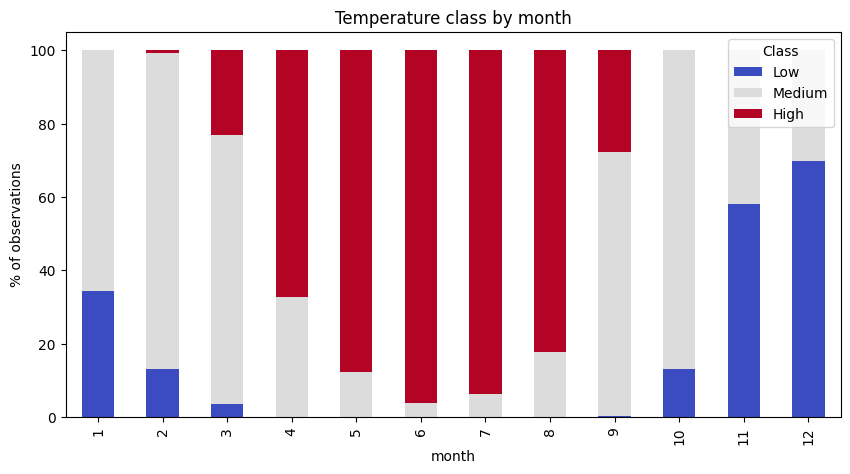

In [22]:
ct = pd.crosstab(b["month"], b["classe"])
chi2, pval, dof, expected = stats.chi2_contingency(ct)

n = ct.values.sum()
cramer_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

print(f"Chi2 = {chi2:.1f} | dof = {dof} | p-value = {pval:.3g}")
print(f"Cramér's V = {cramer_v:.2f}  (0 = independent, 1 = fully dependent)")
print("Minimum expected frequency:", round(expected.min(), 1), "(should be >= 5)")
display(ct)

ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100
ct_pct.plot(kind="bar", stacked=True, figsize=(10, 5), colormap="coolwarm")
plt.ylabel("% of observations"); plt.title("Temperature class by month")
plt.legend(title="Class"); plt.show()

* χ² = 719 853, 22 degrés de liberté, V de Cramér = 0.69 : lien fort. L’effectif attendu minimal (9 304) dépasse largement 5, le test est valide.
  * Low apparaît d’octobre à mars, et presque jamais d’avril à septembre.
  * High n’apparaît presque que de mars à septembre.
  * Medium occupe les mois de transition.
Répartition des classes : Low 15.6 %, Medium 43.8 %, High 40.6 %. La classe Low est minoritaire.



***Attention :*** month est le mois courant, la classe est celle du mois suivant. La ligne « mars » décrit donc la classe d’avril.

## **Multivariante analysis**

| Technique | Question à laquelle elle répond |
|---|---|
| Clustermap | quelles variables forment des familles redondantes ? |
| Profil par classe (heatmap) | quelles variables distinguent Low, Medium et High ? |
| PCA, scree plot | combien de dimensions suffisent pour résumer les 12 variables ? |
| PCA, loadings et biplot | que représente chaque composante ? |
| PCA, projection 2D | les classes ou les mois se séparent-ils dans l'espace réduit ? |
| K-Means + silhouette | les données ont-elles une structure en groupes, et laquelle ? |

In [27]:
# Les 12 variables, centrées-réduites (PCA et K-Means sont sensibles aux échelles)
Xs = pd.DataFrame(StandardScaler().fit_transform(b[VARS]), columns=VARS, index=b.index)

print(Xs.shape)
Xs.describe().loc[["mean", "std"]].round(2)

(754075, 12)


,t2m,d2m,sp,u10,v10,slhf,sshf,ssr,str,e,ro,tp
mean,0.0,0.0,-0.0,0.0,-0.0,0.0,0.0,-0.0,0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


### **Heatmaps / matrice de corrélation:**

***Clustermap et profil par classe : deux heatmaps différentes***

| | Clustermap | Profil par classe |
|---|---|---|
| **Compare** | variable × variable | variable × classe de température |
| **Valeurs** | corrélation de Spearman (de -1 à +1) | moyenne standardisée dans chaque classe |
| **Taille** | 12 × 12 | 12 × 3 |
| **Répond à** | quelles variables se ressemblent entre elles ? | quelles variables distinguent Low, Medium et High ? |


le dendrogramme montre les familles de variables.

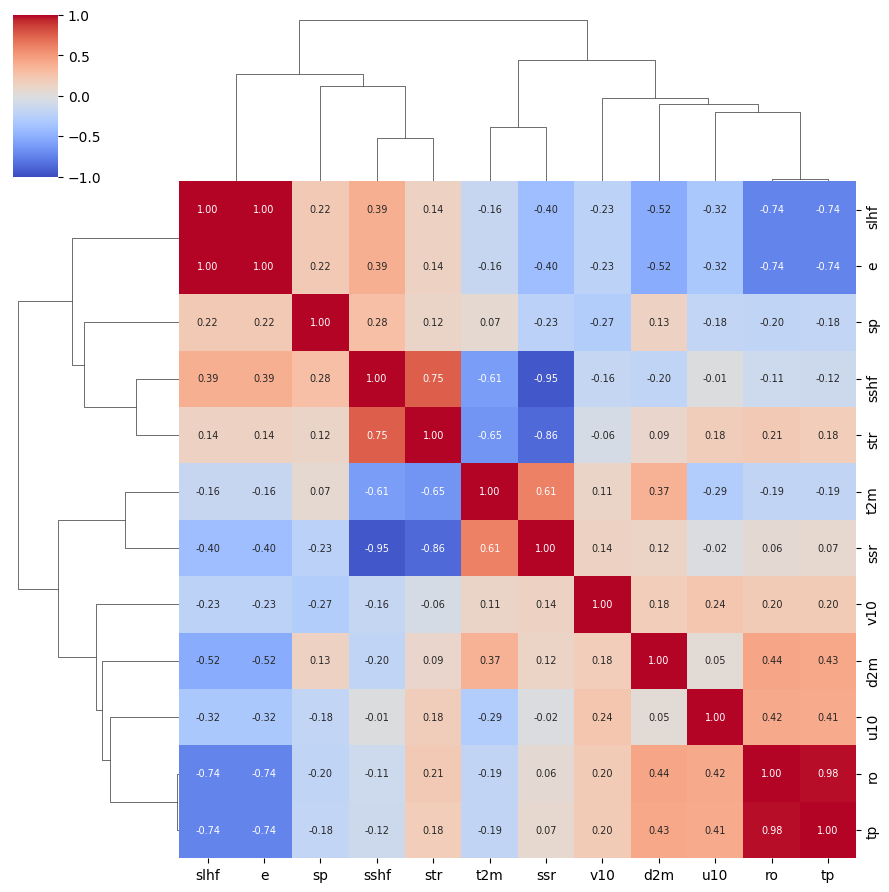

In [28]:
corr = b[VARS].corr(method="spearman")

sns.clustermap(corr, cmap="coolwarm", vmin=-1, vmax=1,
               annot=True, fmt=".2f", annot_kws={"size": 7},
               figsize=(9, 9), method="average")
plt.show()

* **slhf et e :** 1.00. on peut dire que ’un est l’autre multiplié par une constante physique.
* **ro et tp** : 0.98. Le ruissellement est quasi proportionnel aux précipitations
* **ssr, sshf et str**: sont fortement liées (ssr–sshf : -0.95, ssr–str : -0.86, sshf–str : +0.75).
* Plus il y a de rayonnement solaire net, plus le flux de chaleur sensible est négatif (ce qui dépend de la convention de signe d’ERA5).

* **Température :** t2m est liée à ssr (+0.61) et opposée à sshf (-0.61) et str (-0.65). Elle suit donc l’ensoleillement.
* **Hydrologie :** ro et tp s’opposent à slhf et e (-0.74).
* **Variables isolées :** sp, v10, d2m et u10 ont des corrélations faibles avec les autres variables.

heatmap du profil moyen de chaque classe

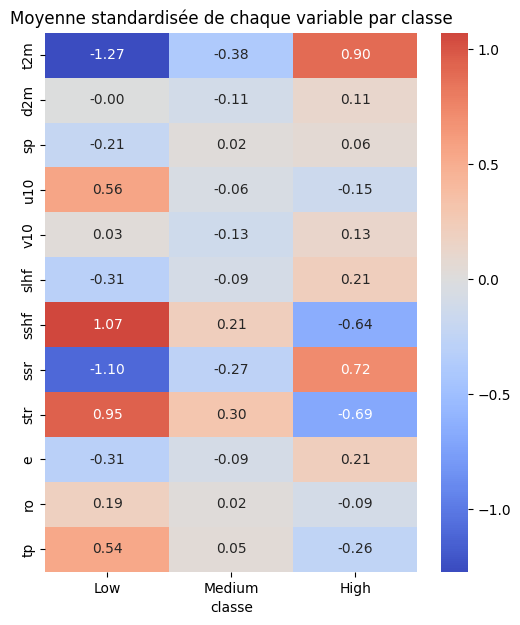

In [29]:
profil = Xs.groupby(b["classe"], observed=True).mean().T     # 12 variables x 3 classes

plt.figure(figsize=(6, 7))
sns.heatmap(profil, cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Moyenne standardisée de chaque variable par classe")
plt.show()

* **Variables discriminantes :** toutes évoluent de façon monotone de Low à High ( soit decriot soit croit).
  * ssr : -1.10, -0.27, +0.72 (la plus discriminante, avec plus de rayonnement solaire quand il fait chaud)
  * sshf : +1.07, +0.21, -0.64
  * str : +0.95, +0.30, -0.69
  * tp : +0.54 pour Low, -0.26 pour High (plus de pluie quand il fait froid), de même que u10 (+0.56 pour Low)
* **Variables peu discriminantes :** d2m, sp, v10, ro, e et slhf ont des moyennes proches de 0 dans les trois classes (|moyenne| ≤ 0.31).

### **PCA visalisation**

variance expliquée (scree plot)

* **% variance :** combien d’information porte une composante.
* **% cumulé :** combien d’information on garde en prenant les k premières, donc c’est lui qui sert à choisir k.

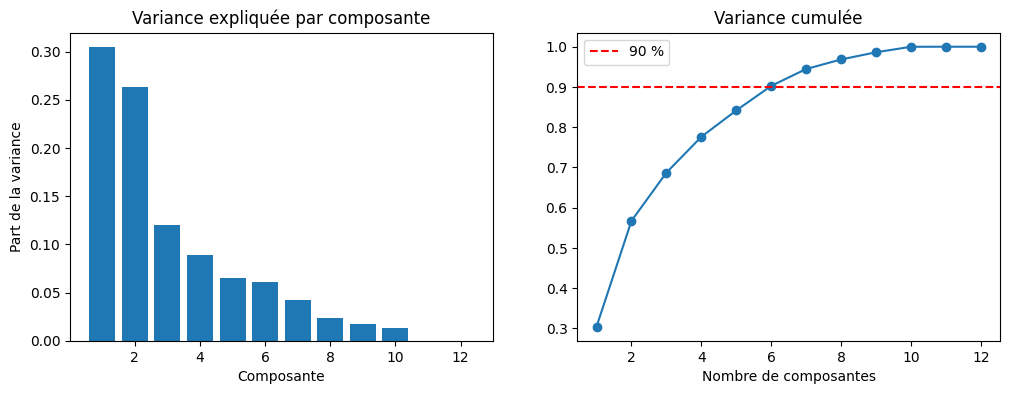

      Valeur propre  % variance  % cumulé
PC1            3.65       30.43     30.43
PC2            3.16       26.30     56.73
PC3            1.44       11.97     68.71
PC4            1.07        8.91     77.61
PC5            0.79        6.56     84.17
PC6            0.73        6.10     90.27
PC7            0.50        4.19     94.46
PC8            0.29        2.38     96.84
PC9            0.21        1.78     98.62
PC10           0.16        1.37     99.99
PC11           0.00        0.01    100.00
PC12           0.00        0.00    100.00
Composantes pour atteindre 90 % : 6
Composantes avec valeur propre > 1 (critère de Kaiser) : 4


In [30]:
pca = PCA().fit(Xs) # cree a PCA  12 nouveaux axes (PC1 à PC12) des combinaisons des 12 variables d’origine. Ils sont classés du plus informatif au moins informatif.
ev  = pca.explained_variance_ratio_ # la part de la variance totale portée par chaque composante.
cum = ev.cumsum()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(range(1, 13), ev)
ax[0].set_title("Variance expliquée par composante")
ax[0].set_xlabel("Composante"); ax[0].set_ylabel("Part de la variance")
ax[1].plot(range(1, 13), cum, "o-")
ax[1].axhline(0.90, color="r", ls="--", label="90 %")
ax[1].set_title("Variance cumulée"); ax[1].set_xlabel("Nombre de composantes")
ax[1].legend()
plt.show()

print(pd.DataFrame({"Valeur propre": pca.explained_variance_,
                    "% variance": ev * 100,
                    "% cumulé": cum * 100},
                   index=[f"PC{i+1}" for i in range(12)]).round(2))

K_PC = int(np.searchsorted(cum, 0.90) + 1)
print("Composantes pour atteindre 90 % :", K_PC)
print("Composantes avec valeur propre > 1 (critère de Kaiser) :", int((pca.explained_variance_ > 1).sum()))

contributions des variables (loadings):

Un poids fort (en valeur absolue) veut dire que la variable construit cette composante. Cela permet de nommer les composantes.

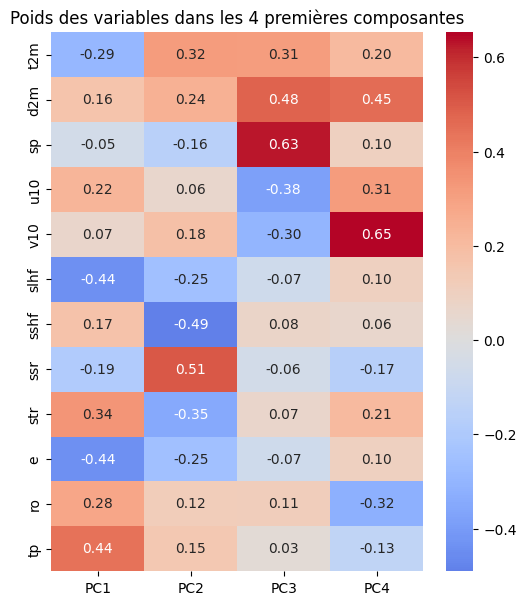

In [31]:
loadings = pd.DataFrame(pca.components_[:4].T, index=VARS,
                        columns=[f"PC{i+1}" for i in range(4)])

plt.figure(figsize=(6, 7))
sns.heatmap(loadings, cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Poids des variables dans les 4 premières composantes")
plt.show()

projection 2D, par classe et par mois

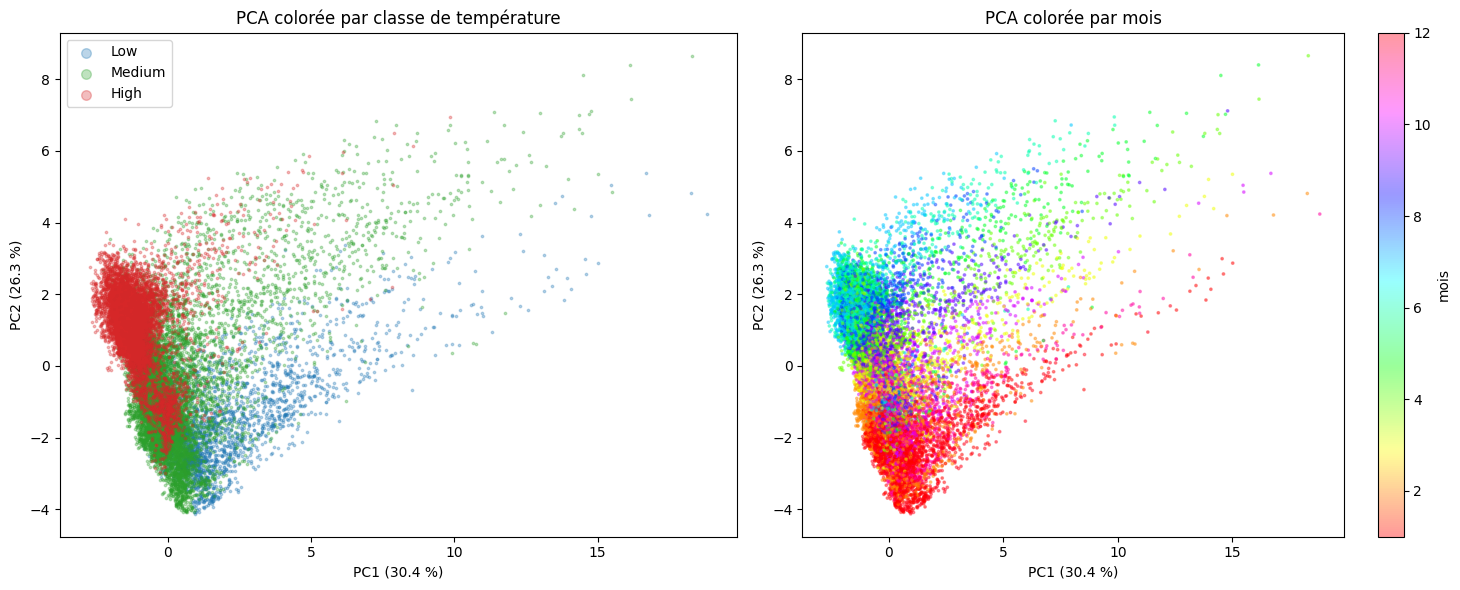

In [36]:
Z = pca.transform(Xs)                                    # scores de toutes les observations
idx = np.random.RandomState(0).choice(len(b), 20000, replace=False)   # sous-échantillon d'affichage
sub = b.iloc[idx]

fig, ax = plt.subplots(1, 2, figsize=(15, 6))

for c, col in zip(["Low", "Medium", "High"], ["tab:blue", "tab:green", "tab:red"]):
    m = (sub["classe"] == c).values
    ax[0].scatter(Z[idx][m, 0], Z[idx][m, 1], s=3, alpha=0.3, c=col, label=c)
ax[0].set_title("PCA colorée par classe de température")
ax[0].legend(markerscale=4)

sc = ax[1].scatter(Z[idx, 0], Z[idx, 1], s=3, alpha=0.4, c=sub["month"], cmap="hsv")
ax[1].set_title("PCA colorée par mois")
plt.colorbar(sc, ax=ax[1], label="mois")

for a in ax:
    a.set_xlabel(f"PC1 ({ev[0]*100:.1f} %)")
    a.set_ylabel(f"PC2 ({ev[1]*100:.1f} %)")
plt.tight_layout()
plt.show()

* Le nuage est dense à gauche, avec une longue traîne vers la droite (PC1 élevé). Ce sont des événements rares, probablement des épisodes de fortes précipitations.

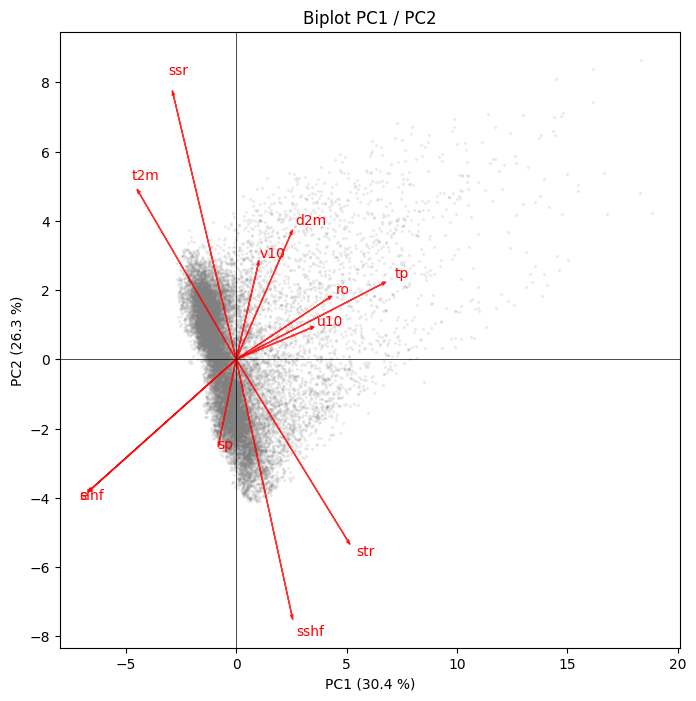

In [33]:
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(Z[idx, 0], Z[idx, 1], s=2, alpha=0.1, color="gray")

scale = np.abs(Z[idx, :2]).max() * 0.8
for i, v in enumerate(VARS):
    x, y = pca.components_[0, i] * scale, pca.components_[1, i] * scale
    ax.arrow(0, 0, x, y, color="red", head_width=0.1, alpha=0.8)
    ax.text(x * 1.08, y * 1.08, v, color="red", fontsize=10)

ax.axhline(0, color="k", lw=0.5); ax.axvline(0, color="k", lw=0.5)
ax.set_xlabel(f"PC1 ({ev[0]*100:.1f} %)"); ax.set_ylabel(f"PC2 ({ev[1]*100:.1f} %)")
ax.set_title("Biplot PC1 / PC2")
plt.show()

### **Clustering**

choix du nombre de clusters (coude et silhouette)

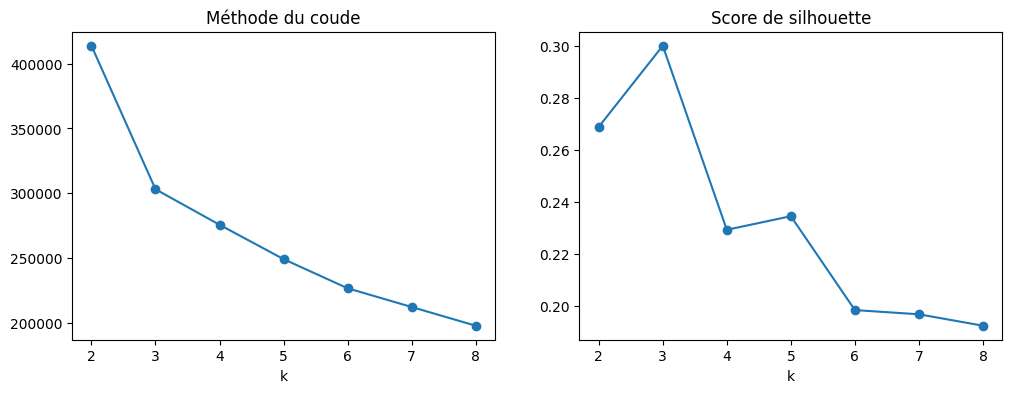

In [34]:
Zk = Z[:, :K_PC]                                # on clusterise sur les composantes retenues
sub_k = np.random.RandomState(1).choice(len(Zk), 50000, replace=False)

ks, inertia, sil = range(2, 9), [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=5, random_state=0).fit(Zk[sub_k])
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Zk[sub_k], km.labels_, sample_size=10000, random_state=0))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertia, "o-"); ax[0].set_title("Méthode du coude"); ax[0].set_xlabel("k")
ax[1].plot(ks, sil, "o-");     ax[1].set_title("Score de silhouette"); ax[1].set_xlabel("k")
plt.show()

K-Means (k = 3) et visualisation

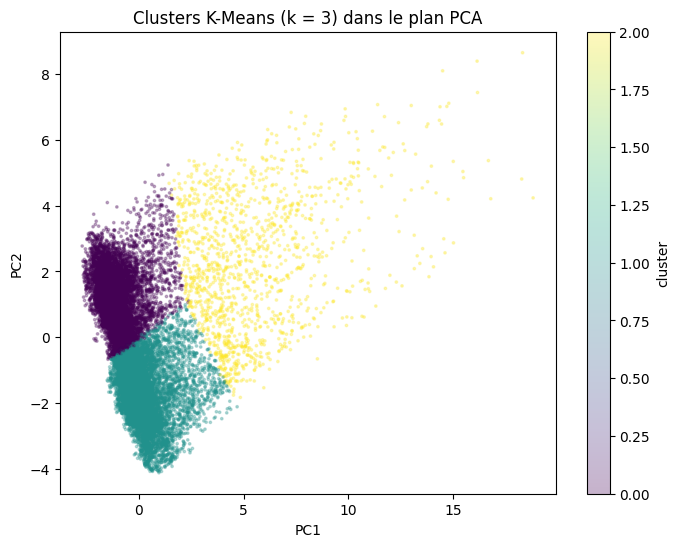

classe    Low  Medium  High
cluster                    
0         0.0    27.0  73.0
1        29.0    61.0  10.0
2        36.0    57.0   7.0
Indice de Rand ajusté (cluster vs classe) : 0.291


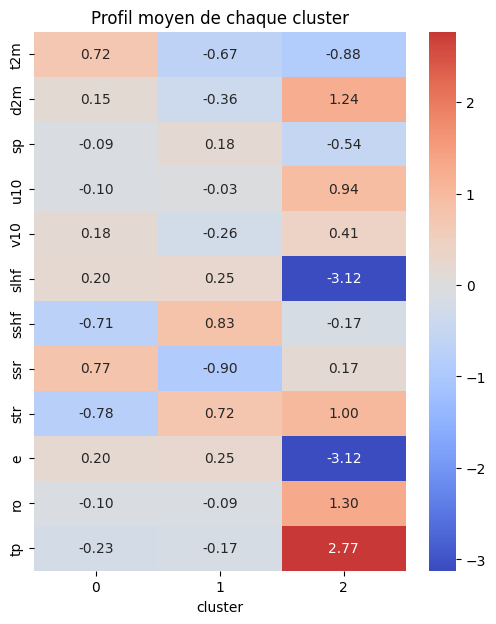

In [35]:
km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(Zk)
b["cluster"] = km.labels_

# Visualisation dans le plan PC1 / PC2
plt.figure(figsize=(8, 6))
plt.scatter(Z[idx, 0], Z[idx, 1], s=3, alpha=0.3, c=b["cluster"].iloc[idx], cmap="viridis")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("Clusters K-Means (k = 3) dans le plan PCA")
plt.colorbar(label="cluster")
plt.show()

# Les clusters retrouvent-ils les classes de température ?
print(pd.crosstab(b["cluster"], b["classe"], normalize="index").round(2) * 100)
print("Indice de Rand ajusté (cluster vs classe) :",
      round(adjusted_rand_score(b["classe"], b["cluster"]), 3))

# Profil moyen de chaque cluster
plt.figure(figsize=(6, 7))
sns.heatmap(Xs.groupby(b["cluster"]).mean().T, cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Profil moyen de chaque cluster")
plt.show()

* Dans le plan PCA, les trois clusters se découpent le nuage sans espace vide entre eux( pourqui ????)

* Comparaison avec les classes de température :

    * Cluster 0 : 73 % High et aucun Low, donc il correspond bien à High.
    * Cluster 1 : 61 % Medium, 29 % Low et 10 % High. Il est mixte, avec une majorité de Medium.
    * Cluster 2 : 57 % Medium et 36 % Low. Il ne représente pas une classe de température, mais un régime météorologique.
    * ARI = 0.291 : l’accord entre clusters et classes est faible à modéré.


Profile des cluster :
* cluster 0 : situation chaude et ensoleillée
* cluster 1 : situation fraîche et peu ensoleillée
* cluster 2 : épisodes pluvieux, humides et venteux (valeurs extrêmes)

Rest a discuter :
Synthèse
* Les 12 variables se résument en deux axes principaux, hydrologique (PC1) et radiatif (PC2). Le second est celui qui est lié à la température.
* Il y a de la redondance (slhf = e, ro ≈ tp) et tu peux l’écrire dans le rapport. Tu peux aussi supprimer e pour la PCA et le K-Means, et vérifier si les résultats changent.
* Le K-Means (k=3) trouve des régimes météorologiques (chaud et ensoleillé, frais, pluvieux) plutôt que les classes de température. Cela explique un ARI faible, qui ne signifie pas que le clustering est mauvais.
* La séparation des classes Low, Medium et High reste partielle, ce qui est cohérent avec la silhouette de 0.30 et le recouvrement dans le plan PCA.